# 01 · EDA — German day-ahead power prices and the 2026 Iran-war gas shock

**Question:** how did the war that started on **28 Feb 2026** (US/Israeli strikes on Iran → Strait of Hormuz
closure → Qatari LNG halted, Ras Laffan hit on 18 Mar) change the statistics of German (DE-LU) day-ahead prices?

**Data — only real observed data, no third-party price forecasts:**
ENTSO-E Transparency (day-ahead prices, TSO load / wind / solar forecasts, actual load), AGSI+ (gas storage),
Yahoo Finance (TTF front-month; KRBN as a rough CO₂ proxy), Open-Meteo archive (weather, analysis only).

To keep seasonality out of the comparison, the crisis window is compared with **the same calendar window one year earlier**.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import PROCESSED_DIR, FIGURES_DIR, CRISIS_START, TZ
from src.events import events_frame
from src import plots
from src.plots import PRE, CRISIS, MUTED, INK_2

plots.setup()
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
save = lambda fig, name: fig.savefig(FIGURES_DIR / f"{name}.png", bbox_inches="tight")

df = pd.read_parquet(PROCESSED_DIR / "dataset.parquet")
local = df.index.tz_convert(TZ)
df["date"] = local.tz_localize(None).normalize()
df["hour"] = local.hour

crisis_start = CRISIS_START.tz_localize(None)
last_day = df["date"].max()
pre_start, pre_end = crisis_start - pd.DateOffset(years=1), last_day - pd.DateOffset(years=1)
df["window"] = np.select(
    [df["date"].between(crisis_start, last_day), df["date"].between(pre_start, pre_end)],
    ["crisis 2026", "same window 2025"], default="other",
)
print(f"Data: {df.index.min():%Y-%m-%d} → {df.index.max():%Y-%m-%d}, {len(df):,} hourly rows")
print(f"Crisis window: {crisis_start:%d %b %Y} → {last_day:%d %b %Y}; baseline: {pre_start:%d %b %Y} → {pre_end:%d %b %Y}")
events_frame()[["date", "label"]]

Data: 2022-12-31 → 2026-10-13, 33,167 hourly rows
Crisis window: 28 Feb 2026 → 13 Oct 2026; baseline: 28 Feb 2025 → 13 Oct 2025


,date,label
0,2026-02-28,War starts (US/Israel strikes on Iran)
1,2026-03-02,Qatar halts LNG output
2,2026-03-18,Missile strike on Ras Laffan (-17% Qatar LNG)
3,2026-04-08,US–Iran ceasefire
4,2026-07-08,"Ceasefire collapses, US strikes resume"


## 0. Data quality

In [2]:
quality = pd.DataFrame({
    "missing_share": df.isna().mean().round(3),
    "first": df.apply(lambda s: s.first_valid_index()).dt.strftime("%Y-%m-%d"),
    "last": df.apply(lambda s: s.last_valid_index()).dt.strftime("%Y-%m-%d"),
})
quality

,missing_share,first,last
price,0.000,2022-12-31,2026-10-13
load_forecast,0.000,2022-12-31,2026-10-13
fc_solar,0.000,2022-12-31,2026-10-13
fc_wind_offshore,0.000,2022-12-31,2026-10-13
fc_wind_onshore,0.000,2022-12-31,2026-10-13
load_actual,0.000,2022-12-31,2026-10-13
residual_load_forecast,0.000,2022-12-31,2026-10-13
w_temperature_2m,0.004,2023-01-01,2026-10-07
w_wind_speed_100m,0.004,2023-01-01,2026-10-07
w_shortwave_radiation,0.004,2023-01-01,2026-10-07


Notes:
* Since **1 Oct 2025** the day-ahead auction clears in 15-minute products; everything is averaged to hourly.
* `ttf_gas`, `carbon_proxy` are lagged **2 days**, `gas_storage_*` **3 days** relative to the delivery day —
  the latest values actually published before the 12:00 CET auction on D-1.
* `load_actual` and `w_*` (actual weather) are kept for analysis only and never enter the model.

## 1. Price regime: before and after 28 Feb 2026

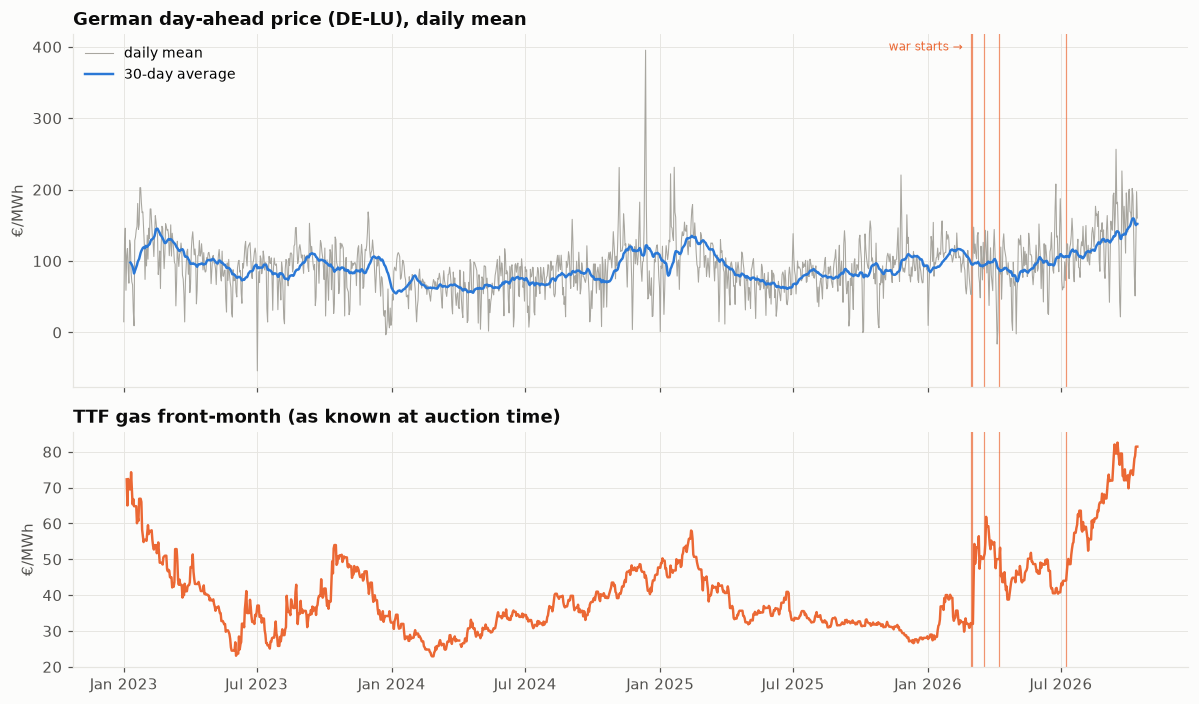

In [3]:
daily = df.groupby("date").agg(price=("price", "mean"), ttf=("ttf_gas", "first"),
                               storage=("gas_storage_full", "first"))
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, height_ratios=[3, 2])
ax1.plot(daily.index, daily["price"], color=MUTED, linewidth=0.7, label="daily mean")
ax1.plot(daily.index, daily["price"].rolling(30, min_periods=10).mean(), color=PRE, label="30-day average")
ax1.set_ylabel("€/MWh")
ax1.set_title("German day-ahead price (DE-LU), daily mean")
ax1.legend(loc="upper left")
plots.mark_events(ax1, label=False)
ax1.text(crisis_start, 0.98, "war starts →  ", transform=ax1.get_xaxis_transform(),
         ha="right", va="top", fontsize=8, color=CRISIS)
ax2.plot(daily.index, daily["ttf"], color=CRISIS)
ax2.set_ylabel("€/MWh")
ax2.set_title("TTF gas front-month (as known at auction time)")
plots.mark_events(ax2, label=False)
plots.date_axis(ax2)
fig.tight_layout(); save(fig, "01_price_and_ttf")

Zoom on 2026, with the war timeline:

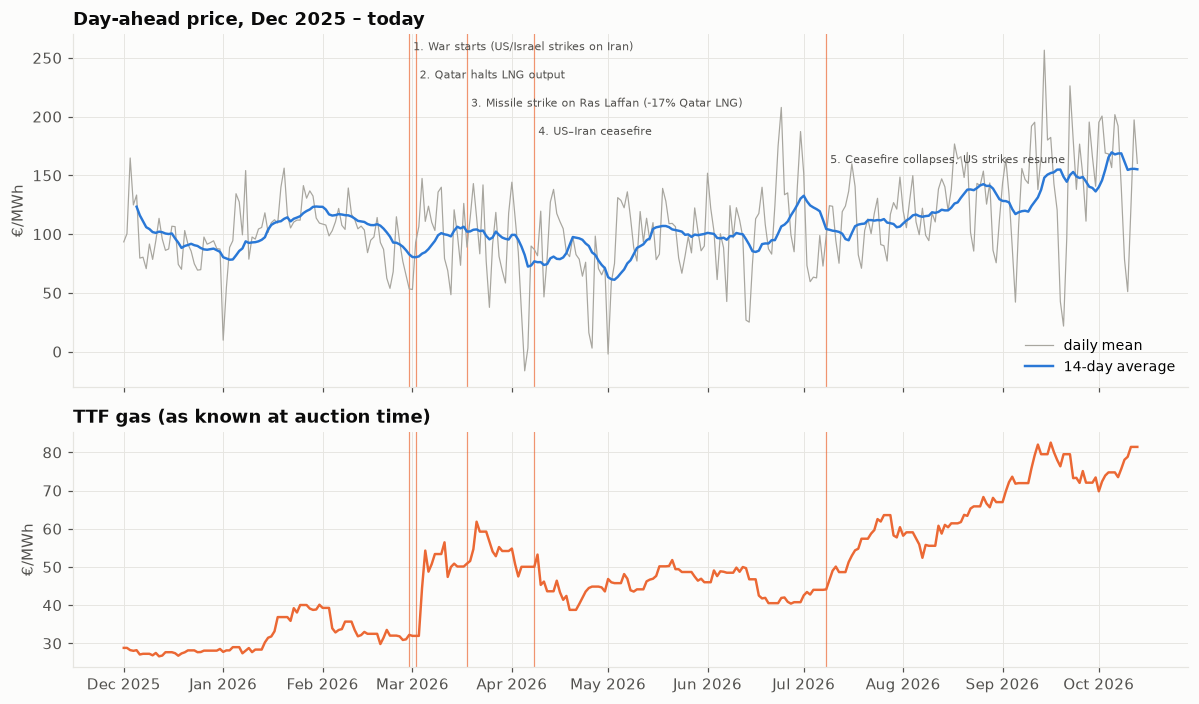

In [4]:
z = daily.loc["2025-12-01":]
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, height_ratios=[3, 2])
ax1.plot(z.index, z["price"], color=MUTED, linewidth=0.8, label="daily mean")
ax1.plot(z.index, z["price"].rolling(14, min_periods=5).mean(), color=PRE, label="14-day average")
ax1.set_ylabel("€/MWh"); ax1.set_title("Day-ahead price, Dec 2025 – today")
ax1.legend(loc="lower right")
plots.mark_events(ax1, numbered=False)
ax2.plot(z.index, z["ttf"], color=CRISIS)
ax2.set_ylabel("€/MWh"); ax2.set_title("TTF gas (as known at auction time)")
plots.mark_events(ax2, label=False)
plots.date_axis(ax2, "%b %Y")
fig.tight_layout(); save(fig, "01b_zoom_2026")

In [5]:
def window_stats(g):
    d = g.groupby("date")["price"]
    return pd.Series({
        "mean price €/MWh": g["price"].mean(),
        "median price": g["price"].median(),
        "std (hourly)": g["price"].std(),
        "95th percentile": g["price"].quantile(0.95),
        "mean daily spread (max-min)": (d.max() - d.min()).mean(),
        "negative-price hours": (g["price"] < 0).sum(),
        "% of hours > 150 €/MWh": (g["price"] > 150).mean() * 100,
        "mean TTF €/MWh": g["ttf_gas"].mean(),
        "mean storage fill %": g["gas_storage_full"].mean(),
        "mean solar forecast MW": g["fc_solar"].mean(),
        "mean wind forecast MW": (g["fc_wind_onshore"] + g["fc_wind_offshore"]).mean(),
    })

summary = df[df["window"] != "other"].groupby("window").apply(window_stats).T
summary = summary[["same window 2025", "crisis 2026"]]
summary["change %"] = (summary["crisis 2026"] / summary["same window 2025"] - 1) * 100
summary.round(1)

window,same window 2025,crisis 2026,change %
mean price €/MWh,79.7,111.3,39.6
median price,89.4,119.8,34.0
std (hourly),52.1,72.7,39.5
95th percentile,148.1,210.1,41.8
mean daily spread (max-min),146.3,182.3,24.6
negative-price hours,548.0,465.0,-15.1
% of hours > 150 €/MWh,4.5,26.9,495.1
mean TTF €/MWh,35.3,55.2,56.3
mean storage fill %,49.6,38.0,-23.5
mean solar forecast MW,11557.2,13562.3,17.3


## 2. Gas storage: the vulnerability going in

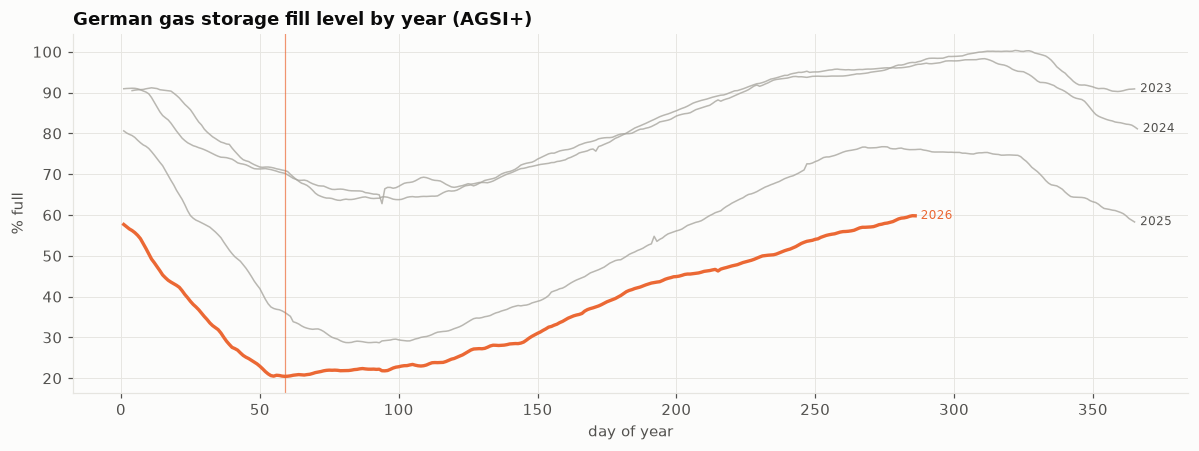

In [6]:
st = daily["storage"].dropna().to_frame()
st["year"], st["doy"] = st.index.year, st.index.dayofyear
fig, ax = plt.subplots()
for year, g in st.groupby("year"):
    is_2026 = year == 2026
    ax.plot(g["doy"], g["storage"], color=CRISIS if is_2026 else MUTED,
            linewidth=2.2 if is_2026 else 1.0, alpha=1 if is_2026 else 0.8)
    ax.text(g["doy"].iloc[-1] + 2, g["storage"].iloc[-1], str(year), fontsize=8,
            color=CRISIS if is_2026 else INK_2, va="center")
ax.axvline(crisis_start.dayofyear, color=CRISIS, linewidth=0.8, alpha=0.7)
ax.set_xlabel("day of year"); ax.set_ylabel("% full")
ax.set_title("German gas storage fill level by year (AGSI+)")
fig.tight_layout(); save(fig, "02_gas_storage")

## 3. How strongly does gas drive power? (daily mean price vs TTF)

2023 – Feb 2026  slope 1.63 €/MWh power per €/MWh gas, intercept 28.0, r=0.39, n=1149
crisis 2026      slope 1.55 €/MWh power per €/MWh gas, intercept 26.0, r=0.44, n=228


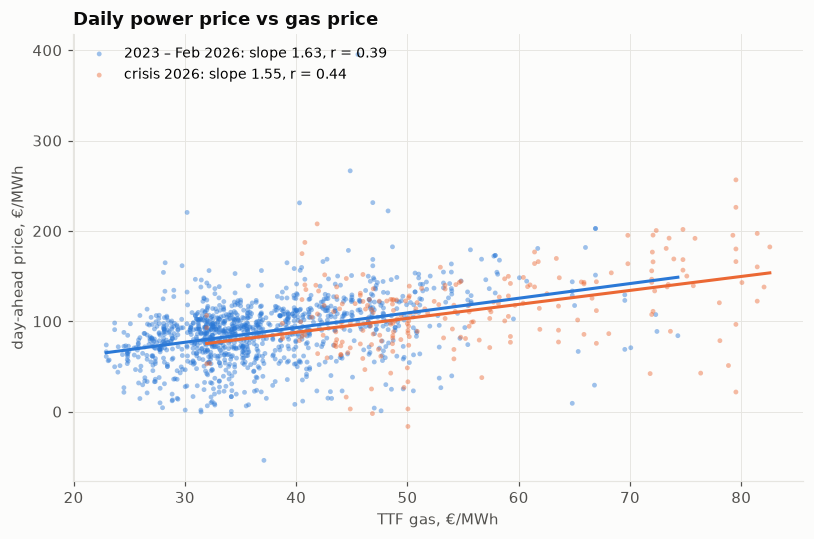

In [7]:
d = daily.dropna(subset=["price", "ttf"]).copy()
d["regime"] = np.where(d.index >= crisis_start, "crisis 2026", "2023 – Feb 2026")
fig, ax = plt.subplots(figsize=(7.5, 5))
for regime, color in [("2023 – Feb 2026", PRE), ("crisis 2026", CRISIS)]:
    g = d[d["regime"] == regime]
    slope, intercept = np.polyfit(g["ttf"], g["price"], 1)
    corr = g[["ttf", "price"]].corr().iloc[0, 1]
    ax.scatter(g["ttf"], g["price"], s=10, alpha=0.45, color=color, edgecolors="none",
               label=f"{regime}: slope {slope:.2f}, r = {corr:.2f}")
    xs = np.linspace(g["ttf"].min(), g["ttf"].max(), 50)
    ax.plot(xs, intercept + slope * xs, color=color, linewidth=2)
    print(f"{regime:16s} slope {slope:.2f} €/MWh power per €/MWh gas, intercept {intercept:.1f}, r={corr:.2f}, n={len(g)}")
ax.set_xlabel("TTF gas, €/MWh"); ax.set_ylabel("day-ahead price, €/MWh")
ax.set_title("Daily power price vs gas price")
ax.legend(loc="upper left")
fig.tight_layout(); save(fig, "03_price_vs_ttf")

The raw scatter mixes gas with renewables (windy days are cheap whatever gas costs).
Controlling for the daily residual load gives a cleaner gas pass-through, and lets us ask:
**how much of the crisis price increase can the gas price explain?**

Physics gives an upper bound: a gas plant with ~50 % efficiency needs ~2 MWh of gas per MWh of power, so in hours
when gas is marginal +1 €/MWh of gas adds ~2 €/MWh to power. Averaged over all hours (gas is not always marginal)
the pass-through should be lower. The regression estimates it, but the estimate depends on the fitting window:

In [8]:
from sklearn.linear_model import LinearRegression

dd = df.groupby("date").agg(price=("price", "mean"), ttf=("ttf_gas", "first"),
                            rl=("residual_load_forecast", "mean")).dropna()
dd["rl"] /= 1000  # GW
win = lambda a, b: dd.loc[a:b].mean()
base, cris = win(pre_start, pre_end), win(crisis_start, last_day)
d_price, d_ttf, d_rl = cris["price"] - base["price"], cris["ttf"] - base["ttf"], cris["rl"] - base["rl"]
print(f"Crisis vs same window 2025: Δprice {d_price:+.1f} €/MWh, ΔTTF {d_ttf:+.1f} €/MWh, Δresidual load {d_rl:+.2f} GW")

fits = {"2023 – Feb 2026": ("2023-01-01", crisis_start - pd.Timedelta(days=1)),
        "2024 – Feb 2026": ("2024-01-01", crisis_start - pd.Timedelta(days=1)),
        "2025 – Feb 2026": ("2025-01-01", crisis_start - pd.Timedelta(days=1)),
        "crisis only":     (crisis_start, last_day)}
rows = []
for name, (a, b) in fits.items():
    g = dd.loc[a:b]
    ols = LinearRegression().fit(g[["ttf", "rl"]], g["price"])
    b_ttf, b_rl = ols.coef_
    rows.append({"fit window": name, "pass-through €/€": b_ttf, "€/MWh per GW residual load": b_rl,
                 "R²": ols.score(g[["ttf", "rl"]], g["price"]),
                 "gas contribution €/MWh": b_ttf * d_ttf, "gas share of Δprice": b_ttf * d_ttf / d_price,
                 "residual-load contribution": b_rl * d_rl,
                 "unexplained €/MWh": d_price - b_ttf * d_ttf - b_rl * d_rl})
pd.DataFrame(rows).set_index("fit window").round(2)

Crisis vs same window 2025: Δprice +31.6 €/MWh, ΔTTF +19.9 €/MWh, Δresidual load -2.99 GW


,pass-through €/€,€/MWh per GW residual load,R²,gas contribution €/MWh,gas share of Δprice,residual-load contribution,unexplained €/MWh
fit window,,,,,,,
2023 – Feb 2026,0.98,2.62,0.78,19.50,0.62,-7.84,19.93
2024 – Feb 2026,1.31,2.55,0.76,26.13,0.83,-7.64,13.11
2025 – Feb 2026,0.65,2.53,0.83,12.90,0.41,-7.56,26.26
crisis only,1.83,3.29,0.73,36.30,1.15,-9.85,5.15


**The split is fragile.** The estimated pass-through ranges from 0.65 to 1.83 depending on the window, so the gas share
of the increase ranges from ~40 % to all of it. A simple regression on 2023 – Feb 2026 attributes ~60 % to gas; with a
pass-through of ~1.6 or more (the crisis-only fit, closer to physics), gas explains the whole increase and no separate
"crisis premium" is left. Part of the instability is a missing variable: there is no EU carbon price in the data.
The robust conclusion is qualitative: **gas is the main driver of the increase; a risk premium on top of it cannot be
identified with this data.**

The drop in residual load (−3.0 GW) pulled prices down. It came mostly from solar (+2.0 GW forecast on average) and
wind (+0.9 GW), with demand almost unchanged (−0.1 GW).

## 4. Merit order: price vs residual load (same season, 2025 vs 2026)

window,crisis 2026,same window 2025
rl_mid,,
-7.5,-1.3,-29.6
-2.5,-0.0,-4.2
2.5,5.1,-1.0
7.5,39.0,0.0
12.5,73.9,13.8
17.5,95.5,56.6
22.5,111.3,76.7
27.5,121.8,88.4
32.5,134.0,96.1


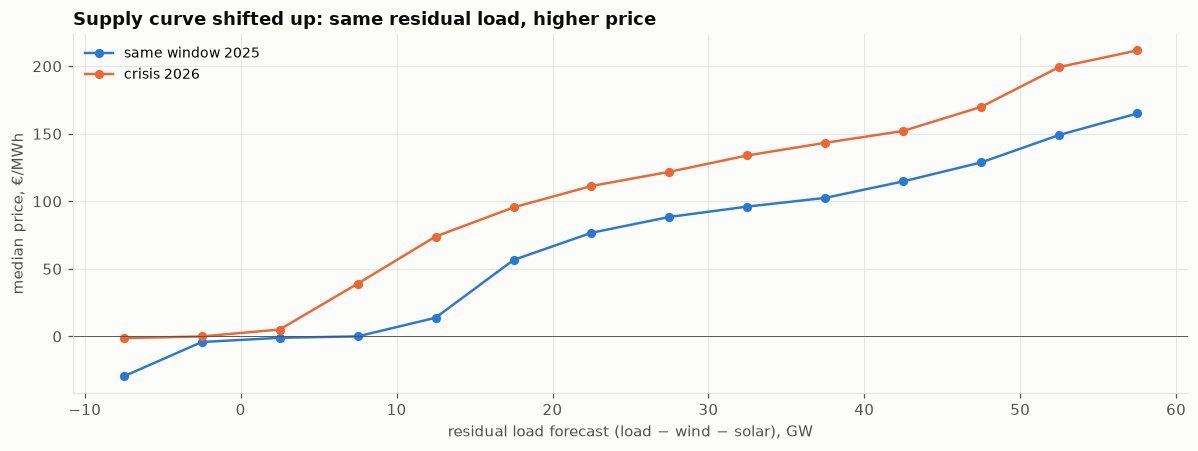

In [9]:
w = df[df["window"] != "other"].dropna(subset=["residual_load_forecast"]).copy()
bins = np.arange(-10_000, 75_001, 5_000)
w["rl_bin"] = pd.cut(w["residual_load_forecast"], bins)
curve = (w.groupby(["window", "rl_bin"], observed=True)["price"].agg(["median", "count"])
           .query("count >= 30").reset_index())
curve["rl_mid"] = curve["rl_bin"].apply(lambda b: b.mid / 1000)
fig, ax = plt.subplots()
for window, color in [("same window 2025", PRE), ("crisis 2026", CRISIS)]:
    g = curve[curve["window"] == window]
    ax.plot(g["rl_mid"], g["median"], color=color, marker="o", markersize=5, label=window)
ax.axhline(0, color=INK_2, linewidth=0.6)
ax.set_xlabel("residual load forecast (load − wind − solar), GW")
ax.set_ylabel("median price, €/MWh")
ax.set_title("Supply curve shifted up: same residual load, higher price")
ax.legend(loc="upper left")
fig.tight_layout(); save(fig, "04_merit_order")
curve.pivot(index="rl_mid", columns="window", values="median").round(1)

## 5. Negative prices: when and why

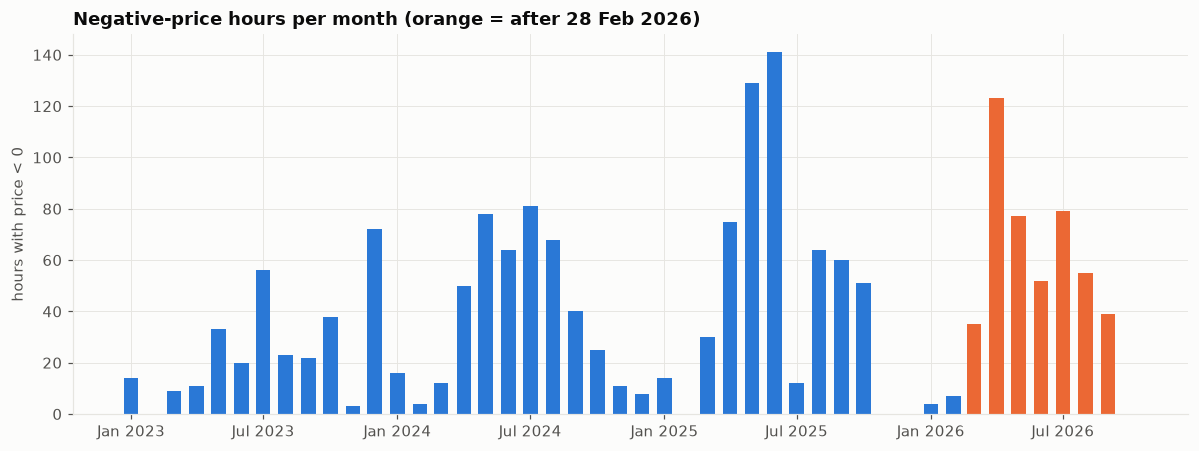

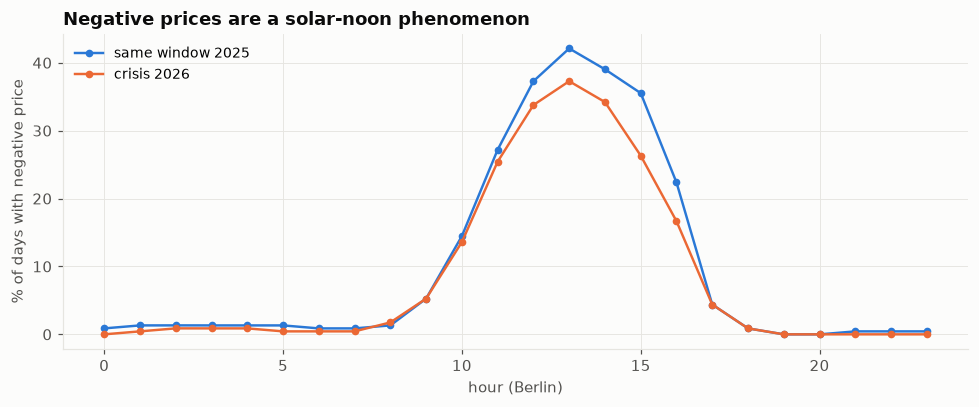

In [10]:
neg = df.assign(neg=df["price"] < 0, ym=df["date"].dt.to_period("M"))
monthly_neg = neg.groupby("ym")["neg"].sum()
fig, ax = plt.subplots()
x = monthly_neg.index.to_timestamp()
ax.bar(x, monthly_neg.values, width=20, color=[CRISIS if t >= crisis_start else PRE for t in x])
ax.set_ylabel("hours with price < 0")
ax.set_title("Negative-price hours per month (orange = after 28 Feb 2026)")
plots.date_axis(ax)
fig.tight_layout(); save(fig, "05_negative_hours")

prof = (neg[neg["window"] != "other"].groupby(["window", "hour"])["neg"].mean() * 100).unstack(0)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(prof.index, prof["same window 2025"], color=PRE, marker="o", markersize=4, label="same window 2025")
ax.plot(prof.index, prof["crisis 2026"], color=CRISIS, marker="o", markersize=4, label="crisis 2026")
ax.set_xlabel("hour (Berlin)"); ax.set_ylabel("% of days with negative price")
ax.set_title("Negative prices are a solar-noon phenomenon")
ax.legend(loc="upper left")
fig.tight_layout(); save(fig, "05b_negative_by_hour")

## 6. Intraday shape: evening peak vs solar trough

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
"crisis − 2025, €/MWh",41.0,39.7,38.2,37.6,36.6,36.1,37.1,33.9,31.7,26.6,...,9.2,12.9,22.1,31.0,36.0,42.8,49.3,51.1,48.7,43.7


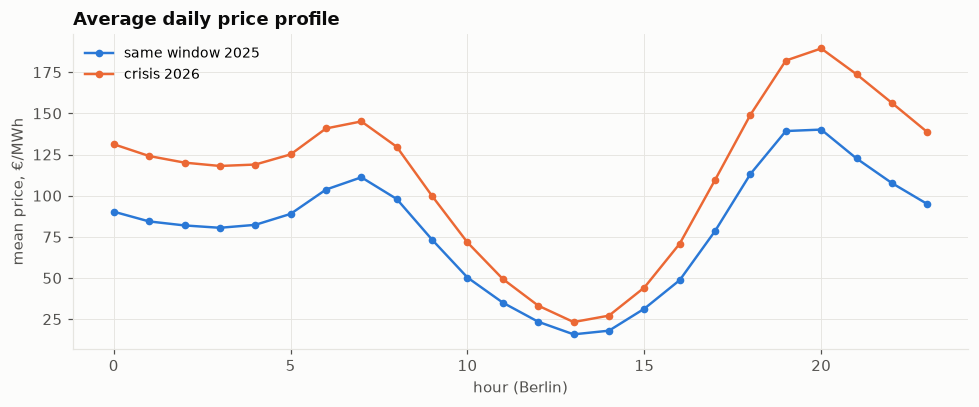

In [11]:
shape = df[df["window"] != "other"].groupby(["window", "hour"])["price"].mean().unstack(0)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(shape.index, shape["same window 2025"], color=PRE, marker="o", markersize=4, label="same window 2025")
ax.plot(shape.index, shape["crisis 2026"], color=CRISIS, marker="o", markersize=4, label="crisis 2026")
ax.set_xlabel("hour (Berlin)"); ax.set_ylabel("mean price, €/MWh")
ax.set_title("Average daily price profile")
ax.legend(loc="upper left")
fig.tight_layout(); save(fig, "06_daily_profile")
(shape["crisis 2026"] - shape["same window 2025"]).round(1).rename("crisis − 2025, €/MWh").to_frame().T

## Takeaways — what the war did to German power prices
*(as of 13 Oct 2026: crisis window 28 Feb – 13 Oct 2026 vs the same window of 2025; numbers from the cells above)*

1. **Price level: +40 %** (mean 79.7 → 111.3 €/MWh), the 95th percentile +42 %, and the share of hours above
   150 €/MWh jumped from 4.5 % to 27 %. TTF gas rose +56 % (35 → 55 €/MWh on average, above 80 by October).
2. **Germany entered the war with nearly empty storage**: ~20 % full at the end of February 2026, the lowest of the
   four years, and still far below previous years in October — the market prices that vulnerability.
3. **Gas is the main driver, but its exact share is not robust.** A regression on 2023 – Feb 2026 attributes ~60 %
   of the +31.6 €/MWh to gas; fitted on other windows the share ranges from ~40 % to 100 %+. Lower residual load
   (mostly more solar and wind) pulled prices down by ~8 €/MWh. Whether a "crisis premium" exists on top of gas cannot
   be identified without a carbon price in the data.
4. **The supply curve shifted up by 35–50 €/MWh** at the same residual load: whenever gas plants are marginal, power is dearer.
5. **The crisis hit evenings, not middays.** Evening hours rose by ~50 €/MWh, solar-noon hours by only ~9 €/MWh;
   negative prices still occur (−15 % hours despite +17 % solar). Wider intraday spreads → more value for flexibility.
6. **Timing matters**: in March–May strong spring solar masked the gas shock; the full effect showed from July,
   when solar faded and the conflict re-escalated.